# Salario mínimo en relación con el salario mediano

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "smi-salario-mediano"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Salario mínimo en relación con el salario mediano"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del salario mediano a tiempo completo"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El salario mínimo legal en porcentaje del salario bruto mediano de los asalariados a tiempo completo (el que separa la mitad que cobra más de la mitad que cobra menos). Es lo que la literatura llama el «índice de Kaitz».

**Cómo se lee.** Un valor de 60 significa que el salario mínimo equivale al 60 % del salario de un asalariado a tiempo completo típico. Cuanto más alto, más cerca está el mínimo de los salarios del centro de la distribución.

**Limitaciones.**
- En EE. UU. se usa el salario mínimo federal; muchos estados y ciudades tienen un mínimo más alto.
- El salario mediano procede de encuestas o registros que difieren entre países.
- La OCDE no publica los agregados de la UE-27 ni de la OCDE.

## 2. Descarga

- **España, EE. UU. y Canadá:** OCDE, *Minimum relative to average wages of full-time workers* (`OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE`, versión 1.0): salario mínimo en % del salario mediano (`MEDIAN`) de los asalariados a tiempo completo.
- **UE-27 y OCDE:** sin dato; la fuente no publica los agregados.
- **Solo para las notas:** la misma ratio sobre el salario medio (`MEAN`), porque la medida `indexacion-smi-salario-medio` toma como referencia el salario medio.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import oecd
from lib.tipos import FuenteMeta

HOY = date.today().isoformat()
AREAS = {"ESP": "espana", "USA": "eeuu", "CAN": "canada", "OECD": "ocde", "EU27_2020": "ue27"}
DATAFLOW = "OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE,1.0"
# Dimensiones: país . medida . unidad . periodo de pago . precios . operación (MEDIAN o MEAN) . sexo
CLAVE = "{AREA}.MR_WG_FT.PT_WG_A_SAL_FT._Z._Z.MEDIAN._Z"

oc, fuentes_oc = oecd.get(DATAFLOW, CLAVE, areas=AREAS, desde=DESDE)
media, _ = oecd.get(DATAFLOW, CLAVE.replace("MEDIAN", "MEAN"), areas=AREAS, desde=DESDE)  # solo para las notas
print(oc.groupby("serie")["periodo"].agg(["min", "max", "count"]))

         min   max  count
serie                    
canada  1976  2025     50
eeuu    1976  2025     50
espana  1976  2025     50


## 3. Transformación

1. La OCDE publica la ratio en porcentaje; se usa tal cual (se comprueba en el código que no es un cociente de 0 a 1).
2. La UE-27 y la OCDE quedan sin dato, con la fuente consultada.
3. **Ratio sobre el salario medio** del último año, para las notas.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"].dropna()  # noqa: E731


def comparar(a, b):
    """Años comunes de dos series y diferencia absoluta entre ellas, en puntos."""
    comunes = sorted(set(a.index) & set(b.index))
    return comunes, (a[comunes] - b[comunes]).abs()


def nota_comparacion(texto, a, b, d=2):
    comunes, dif = comparar(a, b)
    return (f"{texto}: en los {len(comunes)} años comunes ({comunes[0]}-{comunes[-1]}), la diferencia máxima es de "
            f"{es(dif.max(), d)} puntos, en {int(dif.idxmax())}.")


def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, HOY) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]


assert oc["valor"].between(5, 100).all(), "La ratio no está en porcentaje: ¿la OCDE la publica ahora como cociente?"
SIN = (oecd.ORGANISMO, "DSD_EARNINGS@MIN2AVE: la OCDE no publica el agregado", oecd.URL_EXPLORER)
df, fuentes = anadir_sin_dato(oc, fuentes_oc, {s: SIN for s in ["ue27", "ocde"] if s not in set(oc["serie"])})

ULTIMO = int(serie(media, "espana").index.max())
NOTAS = [
    "OCDE, salario mínimo en relación con el salario de los asalariados a tiempo completo (DSD_EARNINGS@MIN2AVE): "
    "salario mínimo legal en porcentaje del salario bruto mediano.",
    f"Sobre el salario bruto medio, en lugar del mediano, la ratio de España en {ULTIMO} es del "
    f"{es(serie(media, 'espana')[ULTIMO])} % (DSD_EARNINGS@MIN2AVE, MEAN). La medida indexacion-smi-salario-medio toma "
    "como referencia el salario medio neto, no el bruto.",
    "EE. UU.: salario mínimo federal; muchos estados y ciudades tienen un salario mínimo más alto.",
    "UE-27 y OCDE: la fuente no publica los agregados y las series quedan vacías (Eurostat solo publica países).",
]
for n in NOTAS:
    print("-", n)
display(df.pivot(index="periodo", columns="serie", values="valor").dropna(how="all").tail(6).round(1))

- OCDE, salario mínimo en relación con el salario de los asalariados a tiempo completo (DSD_EARNINGS@MIN2AVE): salario mínimo legal en porcentaje del salario bruto mediano.
- Sobre el salario bruto medio, en lugar del mediano, la ratio de España en 2025 es del 46,2 % (DSD_EARNINGS@MIN2AVE, MEAN). La medida indexacion-smi-salario-medio toma como referencia el salario medio neto, no el bruto.
- EE. UU.: salario mínimo federal; muchos estados y ciudades tienen un salario mínimo más alto.
- UE-27 y OCDE: la fuente no publica los agregados y las series quedan vacías (Eurostat solo publica países).


serie,canada,eeuu,espana,ocde,ue27
periodo,,,,,
2020,48.9,29.5,51.5,NaN,NaN
2021,48.9,29.1,48.5,NaN,NaN
2022,49.1,27.4,51.0,NaN,NaN
2023,49.6,26.0,52.6,NaN,NaN
2024,49.9,25.0,55.2,NaN,NaN
2025,49.2,24.1,55.3,NaN,NaN


## 4. Visualización

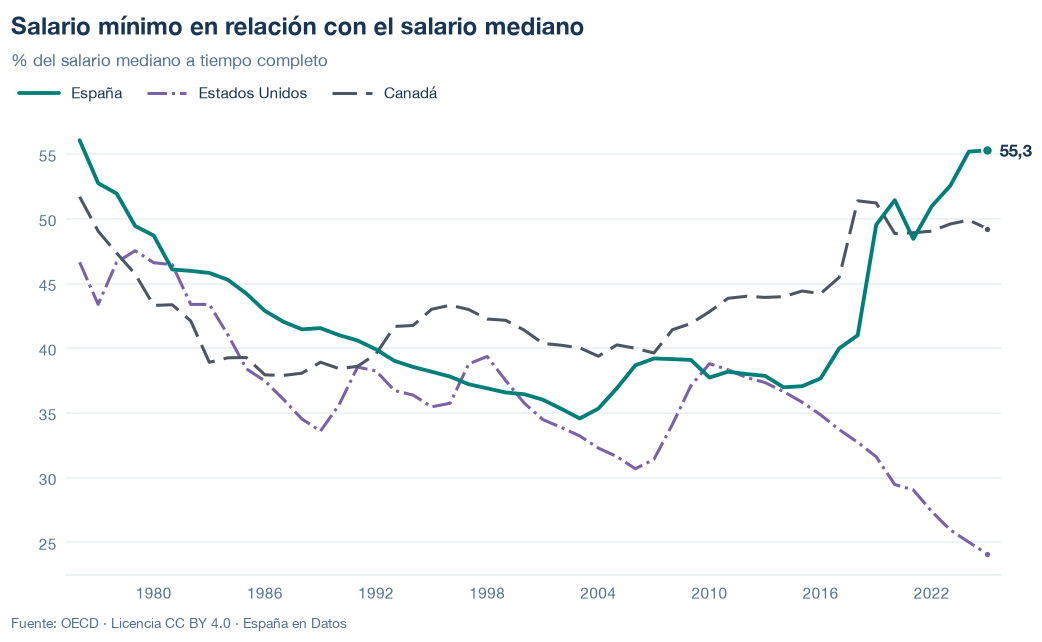

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/smi-salario-mediano.json y data/smi-salario-mediano.csv


## 6. Fuentes, notas y licencia

- OCDE, salario mínimo en relación con el salario medio y mediano: `OECD.ELS.SAE,DSD_EARNINGS@MIN2AVE,1.0` (`MR_WG_FT`, `PT_WG_A_SAL_FT`, `MEDIAN`; `MEAN` solo para las notas).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.